# Import packages

In [ ]:
import os
import re
import glob
import json
import random
from pathlib import Path


import numpy as np
import rasterio

import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR
#from torch.optim.lr_scheduler import LambdaLR
import torch.nn.functional as F
from torchvision.ops import StochasticDepth
import torch.optim as optim
from torchmetrics import JaccardIndex
from lightning import LightningModule, Trainer

from transformers import SegformerConfig, SegformerForSemanticSegmentation
import segmentation_models_pytorch as smp

from tqdm import tqdm

from seapig.scores import EuclideanScore  # or CosineScore, MahalanobisScore, PCAScore, etc.
from seapig import SelectiveInferenceTask


import matplotlib.pyplot as plt
import albumentations as A


c:\ProgramData\anaconda3\envs\slimmebeeldverw\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1008 13:15:06.047000 20284 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


# 1. Dataset Class for Paired TIF & Mask
## Custom Dataset with Albumentations

In [2]:
def preprocess_and_save(feature_paths, mask_paths, output_dir, target_shape=(512, 512)):
    os.makedirs(output_dir, exist_ok=True)
    target_h, target_w = target_shape
    
    for feat_path, mask_path in zip(feature_paths, mask_paths):
        tile_id = os.path.basename(feat_path).replace("Covariates_tile_id_", "").replace(".tif", "")
        out_path = os.path.join(output_dir, f"tile_{tile_id}.pt")
        
        if os.path.exists(out_path):
            continue
            
        with rasterio.open(feat_path) as src:
            x_data = src.read().astype(np.float32)  # (C, H, W)
            
        with rasterio.open(mask_path) as src:
            mask_data = src.read(1).astype(np.int64)  # (H, W)
            
        # 1. Crop first if dimensions are larger than target shape
        c, h, w = x_data.shape
        x_data = x_data[:, :min(h, target_h), :min(w, target_w)]
        mask_data = mask_data[:min(h, target_h), :min(w, target_w)]
        
        # 2. Calculate padding needed to reach 512x512
        _, h, w = x_data.shape
        pad_h = max(0, target_h - h)
        pad_w = max(0, target_w - w)
        
        # Pad right and bottom (0 to top/left, pad_h/pad_w to bottom/right)
        if pad_h > 0 or pad_w > 0:
            # Pad feature channels with NaN (will be converted to valid_mask = False and nan=0.0)
            x_data = np.pad(
                x_data, 
                pad_width=((0, 0), (0, pad_h), (0, pad_w)), 
                mode='constant', 
                constant_values=np.nan
            )
            # Pad target mask with 255 (invalid label, gets mapped to -100)
            mask_data = np.pad(
                mask_data, 
                pad_width=((0, pad_h), (0, pad_w)), 
                mode='constant', 
                constant_values=255
            )

        # 3. Clean NaNs and construct valid masks
        valid_input_mask = ~np.isnan(x_data).any(axis=0)  # (512, 512)
        x_data = np.nan_to_num(x_data, nan=0.0)
        
        target = mask_data.copy()
        invalid_labels = (target == 255) | (target == -1) | (~valid_input_mask)
        target[invalid_labels] = -100  # PyTorch ignore_index
        valid_loss_mask = (~invalid_labels).astype(np.float32)  # (512, 512)
        
        # 4. Save as a single dictionary
        torch.save({
            'x': torch.from_numpy(x_data),                 # (35, 512, 512)
            'target': torch.from_numpy(target).long(),      # (512, 512)
            'valid_mask': torch.from_numpy(valid_loss_mask)  # (512, 512)
        }, out_path)


In [3]:
class PairedSegmentationTiffDataset(Dataset):
    def __init__(self, feature_paths, mask_paths, transform=None):
        """
        feature_paths: List of paths to input Covariates TIF files
        mask_paths: List of paths to corresponding Reference TIF masks
        transform: Albumentations composition pipeline
        """
        self.feature_paths = feature_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.feature_paths)

    def __getitem__(self, idx):
        # 1. Read Feature Image (35 channels, H, W) -> convert to (H, W, 35) for albumentations
        with rasterio.open(self.feature_paths[idx]) as src:
            x_data = src.read().astype(np.float32)  # (C, H, W)
            x_data = np.moveaxis(x_data, 0, -1)     # (H, W, C)

        # 2. Read Reference Mask (1 channel, H, W)
        with rasterio.open(self.mask_paths[idx]) as src:
            mask_data = src.read(1).astype(np.int64)  # (H, W)

        # 3. Handle NaNs/NAs in input data and build spatial valid mask
        valid_input_mask = ~np.isnan(x_data).any(axis=-1)  # Valid across all channels
        x_data = np.nan_to_num(x_data, nan=0.0)

        # 4. Map targets: Invalid values (255, -1) -> -100 for PyTorch ignore_index
        target = mask_data.copy()
        invalid_labels = (target == 255) | (target == -1) | (~valid_input_mask)
        target[invalid_labels] = -100  # PyTorch standard ignored index

        # Create explicit binary mask for custom loss calculations (1 = valid, 0 = ignore)
        valid_loss_mask = (~invalid_labels).astype(np.float32)

        # 5. Apply Synchronized Data Augmentations (Albumentations)
        if self.transform is not None:
            # Pass extra_masks to ensure the valid loss mask transforms identically
            augmented = self.transform(
                image=x_data,
                mask=target,
                valid_mask=valid_loss_mask  # <-- Pass as keyword argument directly
            )
            x_data = augmented['image']
            #x_data = x_data.astype(np.float32)
            target = augmented['mask']
            valid_loss_mask = augmented['valid_mask']

        # 6. Convert back to PyTorch Tensors (CHW layout for images)
        x_tensor = torch.from_numpy(x_data).permute(2, 0, 1)  # Shape: (35, H, W)
        target_tensor = torch.from_numpy(target).long()        # Shape: (H, W)
        valid_mask_tensor = torch.from_numpy(valid_loss_mask)  # Shape: (H, W)

        return x_tensor, target_tensor, valid_mask_tensor



## Albumentations pipeline

In [4]:
def get_train_transforms():
    """Returns spatial transforms for training dataset."""
    return A.Compose(
        [
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
        ],
        additional_targets={'valid_mask': 'mask'}  # Tells Albumentations to treat valid_mask like target mask
    )

## Block-Based Dataset Splitter

In [5]:
def create_block_splits(covariates_dir, reference_dir, val_block_id=9, test_block_id=10):
    """
    Parses directory structure and splits tiles into Train/Val/Test based on block IDs.
    
    covariates_dir (Dir A): Contains Covariates_tile_id_X.tif
    reference_dir (Dir B): Contains block1..block10 subdirectories with Reference_tile_id_X.tif
    """
    train_features, train_masks = [], []
    val_features, val_masks = [], []
    test_features, test_masks = [], []

    # Map target split blocks
    val_block_name = f"block{val_block_id}"
    test_block_name = f"block{test_block_id}"

    # Search for all block subdirectories in reference_dir
    block_dirs = sorted(glob.glob(os.path.join(reference_dir, "block*")))

    for block_path in block_dirs:
        block_name = os.path.basename(block_path)
        ref_files = glob.glob(os.path.join(block_path, "Reference_tile_id_*.tif"))

        for ref_file in ref_files:
            # Extract numerical tile ID
            match = re.search(r'Reference_tile_id_(/d+)/.tif', os.path.basename(ref_file))
            if not match:
                continue
            
            tile_id = match.group(1)
            covariate_file = os.path.join(covariates_dir, f"Covariates_tile_id_{tile_id}.tif")

            # Check matching covariate file exists
            if not os.path.exists(covariate_file):
                print(f"Warning: Covariate file for tile ID {tile_id} not found in {covariates_dir}")
                continue

            # Assign to relevant split
            if block_name == val_block_name:
                val_features.append(covariate_file)
                val_masks.append(ref_file)
            elif block_name == test_block_name:
                test_features.append(covariate_file)
                test_masks.append(ref_file)
            else:
                train_features.append(covariate_file)
                train_masks.append(ref_file)

    print(f"Dataset Split Summary:")
    print(f" - Train samples ({len(block_dirs)-2} blocks): {len(train_features)}")
    print(f" - Validation samples ({val_block_name}): {len(val_features)}")
    print(f" - Test samples ({test_block_name}): {len(test_features)}")

    return (train_features, train_masks), (val_features, val_masks), (test_features, test_masks)

In [6]:
class FastPreprocessedDataset(Dataset):
    def __init__(self, pt_file_paths, transform=None):
        self.pt_file_paths = pt_file_paths
        self.transform = transform

    def __len__(self):
        return len(self.pt_file_paths)

    def __getitem__(self, idx):
        data = torch.load(self.pt_file_paths[idx])
        x_tensor, target_tensor, valid_mask_tensor = data['x'], data['target'], data['valid_mask']

        if self.transform is not None:
            # Convert to (H, W, C) for Albumentations if using spatial transforms
            x_data = x_tensor.permute(1, 2, 0).numpy()
            target = target_tensor.numpy()
            valid_mask = valid_mask_tensor.numpy()

            augmented = self.transform(
                image=x_data,
                mask=target,
                valid_mask=valid_mask
            )
            
            x_tensor = torch.from_numpy(augmented['image']).permute(2, 0, 1)
            target_tensor = torch.from_numpy(augmented['mask']).long()
            valid_mask_tensor = torch.from_numpy(augmented['valid_mask'])

        return x_tensor, target_tensor, valid_mask_tensor

Testjes uitvoeren

In [ ]:
# For fixed train/validation/test splits, you can directly specify the directories where the preprocessed .pt files are stored. This avoids the need to preprocess the data every time you run the script.

#covariates_dir = "G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_covariabelen/blocks/covariates_full_dataset"
#reference_dir = "G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/blocks"

covariates_dir = "C:/Users/sebastiaan_verbessel/Downloads/covariates_full_dataset"
reference_dir = "C:/Users/sebastiaan_verbessel/Downloads/blocks"

train_split, val_split, test_split = create_block_splits(
    covariates_dir, reference_dir, val_block_id=10, test_block_id=9
)


# If you work on tiff files directly, you can use the PairedSegmentationTiffDataset class. However, if you want to speed up training and avoid repeated preprocessing, you can preprocess the data once and save it as .pt files using the preprocess_and_save function. Then, you can use the FastPreprocessedDataset class to load the preprocessed data.
# 2. Instantiate Datasets with Albumentations (only applied to training) 
# train_dataset = PairedSegmentationTiffDataset(
#     feature_paths=train_split[0], 
#     mask_paths=train_split[1], 
#     transform=get_train_transforms()
# )
# val_dataset = PairedSegmentationTiffDataset(
#     feature_paths=val_split[0], 
#     mask_paths=val_split[1], 
#     transform=None
# )
# test_dataset = PairedSegmentationTiffDataset(
#     feature_paths=test_split[0], 
#     mask_paths=test_split[1], 
#     transform=None
# )


dir_train = "E:/preprocessed_train"
dir_val = "E:/preprocessed_val"
dir_test = "E:/preprocessed_test"

# Run the preprocessing and save the .pt files (only needed once)
#preprocess_and_save(train_split[0], train_split[1], dir_train)
#preprocess_and_save(val_split[0], val_split[1], dir_val)
#preprocess_and_save(test_split[0], test_split[1], dir_test)

train_dataset = FastPreprocessedDataset(
    pt_file_paths=sorted(glob.glob(f"{dir_train}/*.pt")), 
    transform=get_train_transforms()
)

val_dataset = FastPreprocessedDataset(
    pt_file_paths=sorted(glob.glob(f"{dir_val}/*.pt")), 
    transform=None
)

test_dataset = FastPreprocessedDataset(
    pt_file_paths=sorted(glob.glob(f"{dir_test}/*.pt")), 
    transform=None
)



# 3. Instantiate DataLoaders
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=0, pin_memory=True)

Dataset Split Summary:
 - Train samples (-2 blocks): 0
 - Validation samples (block10): 0
 - Test samples (block9): 0


### Script to do adaptive train/validation/test splitting based on only pre-processed data (.pt files)

In [ ]:
# ==========================================
# 1. Helper function to resolve .pt paths
# ==========================================
def get_pt_file_paths(selected_blocks, lookup_dict, preprocessed_dirs):
    """Gathers full file paths for all .pt tiles belonging to selected_blocks."""
    # Build a quick search map of filename -> full path across all split directories
    pt_path_map = {}
    for prep_dir in preprocessed_dirs:
        for pt_path in Path(prep_dir).glob("*.pt"):
            pt_path_map[pt_path.name] = str(pt_path)

    # Resolve full paths for chosen blocks
    resolved_paths = []
    for block in selected_blocks:
        pt_filenames = lookup_dict.get(block, [])
        for fname in pt_filenames:
            if fname in pt_path_map:
                resolved_paths.append(pt_path_map[fname])
            else:
                print(f"Warning: {fname} from block {block} not found in preprocessed directories.")

    return sorted(resolved_paths)


# ==========================================
# 2. Setup Directories and Load Lookup Table
# ==========================================
preprocessed_dirs = [
    "E:/preprocessed_train",
    "E:/preprocessed_val",
    "E:/preprocessed_test",
]

# Load the lookup table created in the previous step
with open("block_tile_lookup.json", "r") as f:
    lookup_table = json.load(f)

# All available blocks
all_blocks = list(lookup_table.keys())  # ['block1', 'block2', ..., 'block10']


# ==========================================
# 3. Flexible Block Selection / Splitting
# ==========================================
# # Option A: Manual explicit assignment
# train_blocks = ["block1", "block2", "block3", "block4", "block5", "block6", "block7", "block8"]
# val_blocks = ["block9"]
# test_blocks = ["block10"]


# Randomly select one block for testing
random.seed(42)  # For reproducibility
test_block = random.choice(all_blocks)
test_blocks = [test_block]

# Remaining blocks
remaining_blocks = [b for b in all_blocks if b != test_block]

# Assign training and validation blocks
train_blocks = remaining_blocks[:-1]
val_blocks = remaining_blocks[-1:]

print("Training blocks:", train_blocks)
print("Validation blocks:", val_blocks)
print("Test blocks:", test_blocks)

# Option B: Random split (uncomment if you want randomized block assignments)
# random.seed(42)
# shuffled_blocks = all_blocks.copy()
# random.shuffle(shuffled_blocks)
# train_blocks = shuffled_blocks[:8]
# val_blocks = [shuffled_blocks[8]]
# test_blocks = [shuffled_blocks[9]]


# ==========================================
# 4. Resolve File Paths per Split
# ==========================================
train_pt_paths = get_pt_file_paths(train_blocks, lookup_table, preprocessed_dirs)
val_pt_paths = get_pt_file_paths(val_blocks, lookup_table, preprocessed_dirs)
test_pt_paths = get_pt_file_paths(test_blocks, lookup_table, preprocessed_dirs)

print(f"Train tiles: {len(train_pt_paths)} | Val tiles: {len(val_pt_paths)} | Test tiles: {len(test_pt_paths)}")


# ==========================================
# 5. Instantiate Datasets & DataLoaders
# ==========================================
train_dataset = FastPreprocessedDataset(
    pt_file_paths=train_pt_paths, 
    transform=get_train_transforms()
)

val_dataset = FastPreprocessedDataset(
    pt_file_paths=val_pt_paths, 
    transform=None
)

test_dataset = FastPreprocessedDataset(
    pt_file_paths=test_pt_paths, 
    transform=None
)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=0, pin_memory=True)

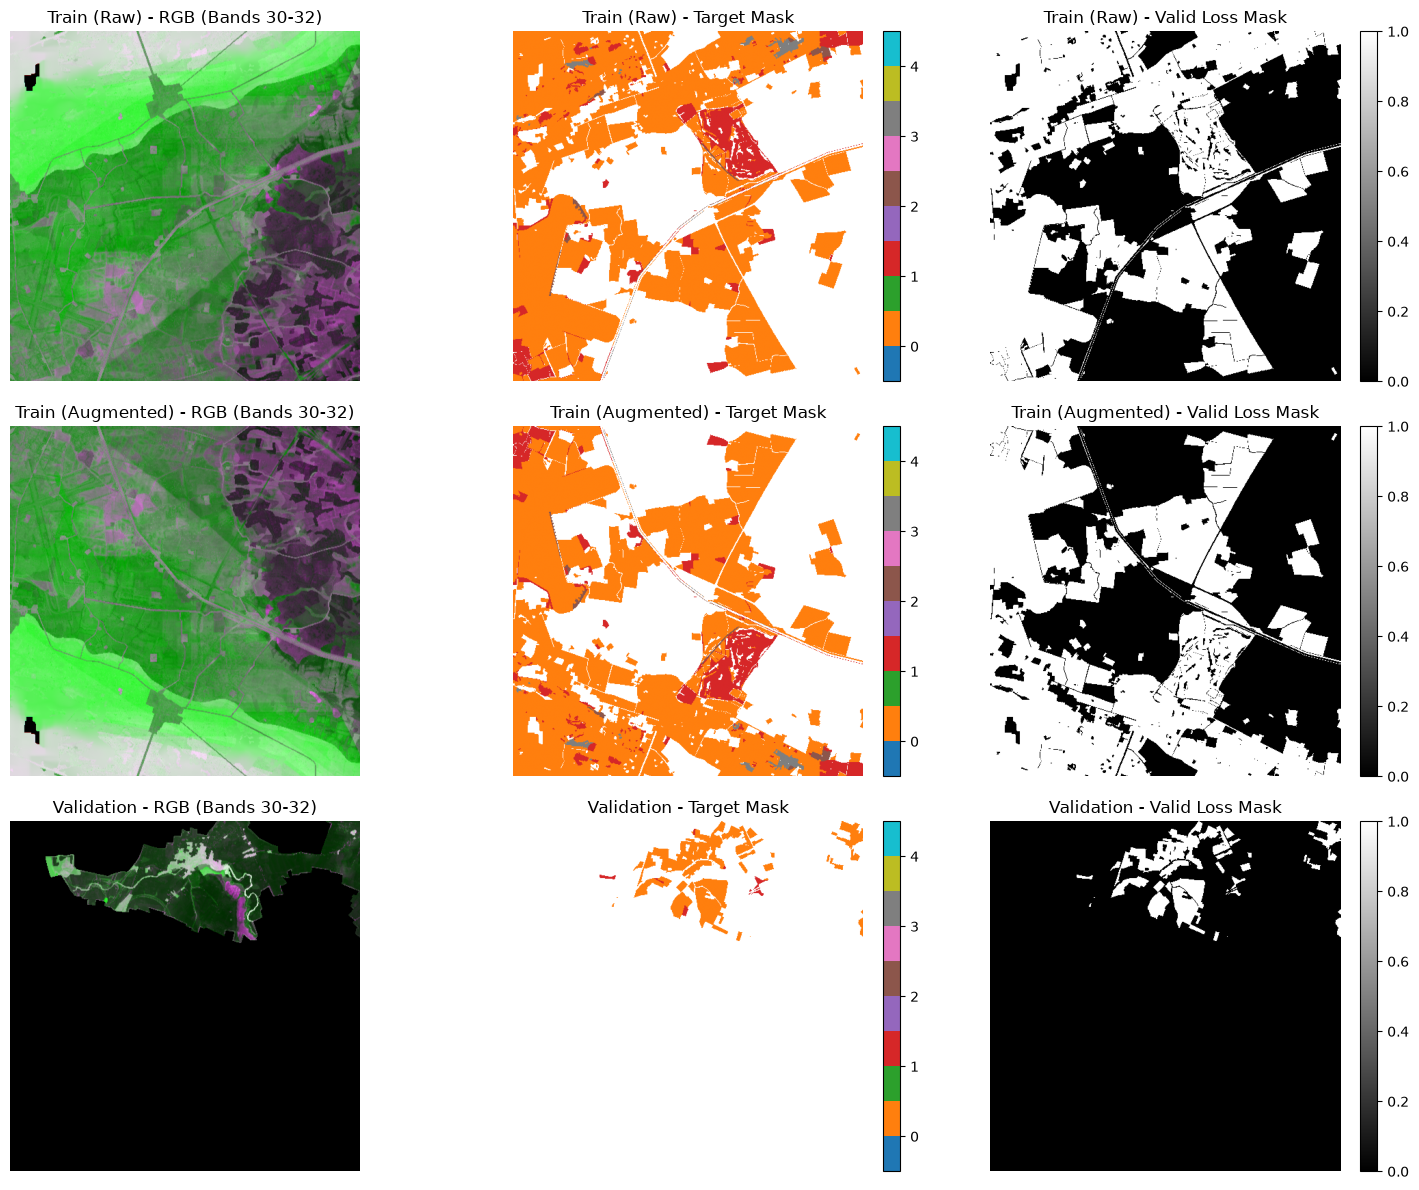

In [8]:
def visualize_dataset_samples(dataset_with_transform, dataset_without_transform, val_dataset):
    """
    Visualizes:
    1. Raw (unaugmented) train image + target mask + valid mask
    2. Augmented train image + target mask + valid mask
    3. Validation image + target mask + valid mask
    
    Renders RGB representation using channels [30, 31, 32].
    """
    # 1. Fetch Raw Train Sample (without transform)
    x_train_raw, target_train_raw, mask_train_raw = dataset_without_transform[80]
    
    # 2. Fetch Augmented Train Sample (with transform)
    x_train_aug, target_train_aug, mask_train_aug = dataset_with_transform[80]
    
    # 3. Fetch Validation Sample
    x_val, target_val, mask_val = val_dataset[80]

    def prep_rgb(tensor):
        # Convert (C, H, W) tensor to (H, W, C) numpy array and select 3 channels
        img = tensor[30:33, :, :].permute(1, 2, 0).cpu().numpy()
        # Min-max normalization per channel for clear visualization
        img_min = img.min(axis=(0, 1), keepdims=True)
        img_max = img.max(axis=(0, 1), keepdims=True)
        denom = img_max - img_min
        denom[denom == 0] = 1.0
        return (img - img_min) / denom

    # Prepare plotting grid
    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    
    rows = [
        ("Train (Raw)", prep_rgb(x_train_raw), target_train_raw.numpy(), mask_train_raw.numpy()),
        ("Train (Augmented)", prep_rgb(x_train_aug), target_train_aug.numpy(), mask_train_aug.numpy()),
        ("Validation", prep_rgb(x_val), target_val.numpy(), mask_val.numpy()),
    ]

    for row_idx, (row_label, img_rgb, target, valid_mask) in enumerate(rows):
        # RGB Feature Representation
        axes[row_idx, 0].imshow(img_rgb)
        axes[row_idx, 0].set_title(f"{row_label} - RGB (Bands 30-32)")
        axes[row_idx, 0].axis("off")

        # Target Reference Mask
        # im_target = axes[row_idx, 1].imshow(target, cmap="tab10", vmin=-100, vmax=target.max())
        # axes[row_idx, 1].set_title(f"{row_label} - Target Mask")
        # axes[row_idx, 1].axis("off")
        # plt.colorbar(im_target, ax=axes[row_idx, 1], fraction=0.046, pad=0.04)

        # Mask out -100 using a NumPy masked array
        masked_target = np.ma.masked_equal(target, -100)

        # Set background color of the axis (e.g., dark gray or black) to show where -100 was
        axes[row_idx, 1].set_facecolor('lightgray') 

        # Display classes 0 to 4 clearly
        im_target = axes[row_idx, 1].imshow(masked_target, cmap="tab10", vmin=-0.5, vmax=4.5)
        axes[row_idx, 1].set_title(f"{row_label} - Target Mask")
        axes[row_idx, 1].axis("off")

        # Add colorbar with discrete ticks 0, 1, 2, 3, 4
        cbar = plt.colorbar(im_target, ax=axes[row_idx, 1], fraction=0.046, pad=0.04, ticks=range(5))
        cbar.ax.set_yticklabels(['0', '1', '2', '3', '4'])

        # Valid Loss Mask
        im_valid = axes[row_idx, 2].imshow(valid_mask, cmap="gray", vmin=0, vmax=1)
        axes[row_idx, 2].set_title(f"{row_label} - Valid Loss Mask")
        axes[row_idx, 2].axis("off")
        plt.colorbar(im_valid, ax=axes[row_idx, 2], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

# --- Execution ---
# Create an unaugmented dataset instance for the raw training comparison
train_dataset_raw = FastPreprocessedDataset(
    pt_file_paths=sorted(glob.glob(f"{dir_train}/*.pt")), 
    transform=None
)

visualize_dataset_samples(
    dataset_with_transform=train_dataset,
    dataset_without_transform=train_dataset_raw,
    val_dataset=val_dataset
)

# 2. Standard U-Net (BatchNorm + ReLU)

In [9]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch, p_drop=0.0):
        super(DoubleConv, self).__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        ]
        if p_drop > 0.0:
            layers.append(nn.Dropout2d(p=p_drop))
            
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    def __init__(self, in_channels=35, num_classes=4, drop_rate=0.2):
        super(UNet, self).__init__()

        # Encoder
        self.inc = DoubleConv(in_channels, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512))
        
        # Bottleneck (applying dropout at the deepest layer)
        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(512, 1024, p_drop=drop_rate))

        # Decoder with Skip/Cross Connections
        self.up1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(1024, 512, p_drop=drop_rate)

        self.up2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(512, 256, p_drop=drop_rate)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(256, 128)

        self.up4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_up4 = DoubleConv(128, 64)

        # Output Head
        self.outc = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward_features(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        # Extract global representation via Global Average Pooling on bottleneck
        embedding = F.adaptive_avg_pool2d(x5, (1, 1)).squeeze(-1).squeeze(-1)  # Shape: (B, C)

        x = self.up1(x5)
        x = torch.cat([x, x4], dim=1)
        x = self.conv_up1(x)

        x = self.up2(x)
        x = torch.cat([x, x3], dim=1)
        x = self.conv_up2(x)

        x = self.up3(x)
        x = torch.cat([x, x2], dim=1)
        x = self.conv_up3(x)

        x = self.up4(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv_up4(x)
        logits = self.outc(x)

        return logits, embedding

    def forward(self, batch: tuple[torch.Tensor, torch.Tensor] | torch.Tensor) -> torch.Tensor:
        """Standard PyTorch forward pass."""
        images = batch[0] if isinstance(batch, (tuple, list)) else batch
        logits, _ = self.forward_features(images)
        return logits

    def extract(self, batch: tuple[torch.Tensor, torch.Tensor]) -> dict[str, torch.Tensor]:
        """
        Required by seapig for automated batch-wise extraction.
        Returns a dictionary containing 'prediction', 'embedding', and 'label'.
        """
        # Unpack images and labels safely regardless of extra elements in batch
        images = batch[0]
        labels = batch[1]

        # Ensure images (and labels if needed) are on the same device as model parameters
        device = next(self.parameters()).device
        images = images.to(device)

        logits, embedding = self.forward_features(images)

        return {
            "prediction": logits,
            "embedding": embedding,
            "label": labels,
        }

# 3. ResNet-Encoder U-Net (with Skip Connections)

In [10]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, drop_path_rate=0.0):
        super(ResBlock, self).__init__()
        self.conv1 = nn.Conv2d(
            in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_ch)

        # DropPath / Stochastic Depth applied to the residual branch
        self.drop_path = (
            StochasticDepth(p=drop_path_rate, mode="batch")
            if drop_path_rate > 0.0
            else nn.Identity()
        )

        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_ch, out_ch, kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_ch),
            )

    def forward(self, x):
        residual = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        # Drop the residual path during training with probability drop_path_rate
        out = self.drop_path(out) + residual
        return self.relu(out)


class ResNetUNet(nn.Module):
    def __init__(self, in_channels=35, num_classes=4, max_drop_path=0.2):
        super(ResNetUNet, self).__init__()

        # Linear schedule for Stochastic Depth across encoder blocks
        # enc1: 0.0, enc2: ~0.05, enc3: ~0.10, enc4: ~0.15, bottleneck: 0.20
        rates = torch.linspace(0, max_drop_path, 5).tolist()

        # Stem
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )

        # Encoder with Stochastic Depth
        self.enc1 = ResBlock(64, 64, stride=1, drop_path_rate=rates[0])
        self.enc2 = ResBlock(64, 128, stride=2, drop_path_rate=rates[1])
        self.enc3 = ResBlock(128, 256, stride=2, drop_path_rate=rates[2])
        self.enc4 = ResBlock(256, 512, stride=2, drop_path_rate=rates[3])
        self.bottleneck = ResBlock(512, 1024, stride=2, drop_path_rate=rates[4])

        # Decoder (Standard DoubleConv with Dropout2d for non-residual blocks)
        self.up1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(1024, 512, p_drop=0.2)

        self.up2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(512, 256, p_drop=0.2)

        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(256, 128, p_drop=0.0)

        self.up4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(128, 64, p_drop=0.0)

        # Output Head
        self.outc = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward_features(self, x):
        x_stem = self.stem(x)
        e1 = self.enc1(x_stem)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        b = self.bottleneck(e4)
        # Extract global representation via Global Average Pooling on bottleneck
        embedding = F.adaptive_avg_pool2d(b, (1, 1)).squeeze(-1).squeeze(-1)  # Shape: (B, C)

        d1 = self.dec1(torch.cat([self.up1(b), e4], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d1), e3], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d2), e2], dim=1))
        d4 = self.dec4(torch.cat([self.up4(d3), e1], dim=1))
        logits = self.outc(d4)

        return logits, embedding
    
    def forward(self, batch: tuple[torch.Tensor, torch.Tensor] | torch.Tensor) -> torch.Tensor:
        """Standard PyTorch forward pass."""
        images = batch[0] if isinstance(batch, (tuple, list)) else batch
        logits, _ = self.forward_features(images)
        return logits
    

    def extract(self, batch: tuple[torch.Tensor, torch.Tensor]) -> dict[str, torch.Tensor]:
        """
        Required by seapig for automated batch-wise extraction.
        Returns a dictionary containing 'prediction', 'embedding', and 'label'.
        """
        # Unpack images and labels safely regardless of extra elements in batch
        images = batch[0]
        labels = batch[1]

        # Ensure images (and labels if needed) are on the same device as model parameters
        device = next(self.parameters()).device
        images = images.to(device)

        logits, embedding = self.forward_features(images)

        return {
            "prediction": logits,
            "embedding": embedding,
            "label": labels,
        }



# 4. SK-ResNeXTUNET


In [11]:
# define selective kernel module 
class SKConv(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, M=2, r=32, L=32):
        """
        M: Number of branches (e.g., 3x3, 5x5 kernels)
        r: Reduction ratio for channel attention
        L: Minimum dimension for attention vector
        """
        super(SKConv, self).__init__()
        d = max(int(out_channels / r), L)
        self.M = M
        self.out_channels = out_channels
        self.convs = nn.ModuleList([])
        
        for i in range(M):
            # Branch i with increasing dilation/kernel size
            self.convs.append(
                nn.Sequential(
                    nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, 
                              padding=1+i, dilation=1+i, bias=False),
                    nn.BatchNorm2d(out_channels),
                    nn.ReLU(inplace=True)
                )
            )
            
        self.fc = nn.Linear(out_channels, d)
        self.fcs = nn.ModuleList([])
        for i in range(M):
            self.fcs.append(nn.Linear(d, out_channels))
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        
        
        # 1. Feature extraction from M branches
        feats = [conv(x) for conv in self.convs]
        U = sum(feats)
        
        # 2. Global average pooling
        S = U.mean(-1).mean(-1)
        Z = self.fc(S)
        
        # 3. Softmax attention across branches
        weights = [fc(Z) for fc in self.fcs]
        weights = torch.stack(weights, dim=1) # (batch_size, M, out_channels)
        weights = self.softmax(weights)
        
        # 4. Weighted sum of features
        V = sum(weights[:, i, :].unsqueeze(-1).unsqueeze(-1) * feats[i] for i in range(self.M))
        return V

# define decoder block
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels, drop_rate=0.2):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        
        self.conv = nn.Sequential(
            nn.Conv2d((in_channels // 2) + skip_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout2d(p=drop_rate), # <--- Spatial Dropout added after ReLU
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Dropout2d(p=drop_rate)  # <--- Spatial Dropout added after ReLU
        )

    def forward(self, x, skip=None):
        x = self.up(x)
        if skip is not None:
            if x.shape != skip.shape:
                x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=True)
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)

# encoder-decoder
class SKResNeXtUNet(nn.Module):
    def __init__(self, in_channels=35, num_classes=4, drop_rate=0.2):
        super().__init__()
        
        # Encoder Stage 1
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=7, stride=1, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        
        # Encoder Stage 2
        self.pool1 = nn.MaxPool2d(2, 2)
        self.enc2 = SKConv(64, 128)
        
        # Encoder Stage 3
        self.pool2 = nn.MaxPool2d(2, 2)
        self.enc3 = SKConv(128, 256)
        
        # Encoder Stage 4
        self.pool3 = nn.MaxPool2d(2, 2)
        self.enc4 = SKConv(256, 512)
        
        # Bottleneck + Dropout
        self.pool4 = nn.MaxPool2d(2, 2)
        self.bottleneck = nn.Sequential(
            SKConv(512, 1024),
            nn.Dropout2d(p=drop_rate) # <--- Dropout at the bottleneck
        )
        
        # Decoder (passing drop_rate to blocks)
        self.dec4 = DecoderBlock(1024, 512, 512, drop_rate=drop_rate)
        self.dec3 = DecoderBlock(512, 256, 256, drop_rate=drop_rate)
        self.dec2 = DecoderBlock(256, 128, 128, drop_rate=drop_rate)
        self.dec1 = DecoderBlock(128, 64, 64, drop_rate=drop_rate)
        
        self.final_conv = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward_features(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        
        b = self.bottleneck(self.pool4(e4))
        embedding = F.adaptive_avg_pool2d(b, (1, 1)).squeeze(-1).squeeze(-1)  # Shape: (B, C)

        
        d4 = self.dec4(b, e4)
        d3 = self.dec3(d4, e3)
        d2 = self.dec2(d3, e2)
        d1 = self.dec1(d2, e1)
        logits = self.final_conv(d1)
        
        return logits, embedding

    def forward(self, batch: tuple[torch.Tensor, torch.Tensor] | torch.Tensor) -> torch.Tensor:
        """Standard PyTorch forward pass."""
        images = batch[0] if isinstance(batch, (tuple, list)) else batch
        logits, _ = self.forward_features(images)
        return logits

    def extract(self, batch: tuple[torch.Tensor, torch.Tensor]) -> dict[str, torch.Tensor]:
        """
        Required by seapig for automated batch-wise extraction.
        Returns a dictionary containing 'prediction', 'embedding', and 'label'.
        """
        # Unpack images and labels safely regardless of extra elements in batch
        images = batch[0]
        labels = batch[1]
    
        # Ensure images (and labels if needed) are on the same device as model parameters
        device = next(self.parameters()).device
        images = images.to(device)
    
        logits, embedding = self.forward_features(images)
    
        return {
            "prediction": logits,
            "embedding": embedding,
            "label": labels,
        }

# 5. Segformer

In [18]:
class SegFormerFeatureModel(nn.Module):
    """
    SegFormer model wrapper that returns both the segmentation logits
    and the intermediate/bottleneck feature embeddings.
    
    Compatible with input tensors of shape (B, C_in, H, W).
    """
    def __init__(
        self, 
        in_channels=35, 
        num_classes=4, 
        architecture="nvidia/mit-b0", 
        reshape_features=True
        ):
        super().__init__()
        self.in_channels = in_channels
        self.num_classes = num_classes
        self.reshape_features = reshape_features

        # 1. Configure SegFormer
        config = SegformerConfig.from_pretrained(architecture)
        config.num_channels = in_channels
        config.num_labels = num_classes
        config.reshape_last_stage = True
        
        # Disable pretrained weights if input channels differ from standard RGB (3)
        if in_channels != 3:
            self.model = SegformerForSemanticSegmentation(config)
        else:
            self.model = SegformerForSemanticSegmentation.from_pretrained(
                architecture, 
                config=config, 
                ignore_mismatched_sizes=True
            )

    def forward_features(self, x):
        """
        Forward pass returning both final segmentation logits and feature embeddings.
        
        Args:
            x (torch.Tensor): Input tensor of shape (B, C, H, W)
            
        Returns:
            tuple:
                - logits (torch.Tensor): Output segmentation map, resized to match input (B, num_classes, H, W)
                - embeddings (torch.Tensor): Global pooled feature representation of shape (B, C_last)
        """
        input_spatial_shape = x.shape[-2:] # (H, W)

        # Pass through the SegFormer base model
        outputs = self.model.segformer(
            x,
            output_hidden_states=True,
            return_dict=True
        )
        
        # Extract stage feature maps from MiT encoder
        hidden_states = outputs.hidden_states

        # Extract the highest-level semantic feature map (bottleneck)
        # Shape: (B, C_last, H/32, W/32)
        embeddings = hidden_states[-1]

        # Apply Global Average Pooling over spatial dimensions (H, W) -> (B, C_last)
        embeddings = embeddings.mean(dim=(-2, -1))

        # Pass encoder states through SegFormer Decode Head
        logits = self.model.decode_head(hidden_states) # Shape: (B, num_classes, H/4, W/4)

        # Upsample logits back to match input spatial dimensions (H, W)
        logits = F.interpolate(
            logits, 
            size=input_spatial_shape, 
            mode="bilinear", 
            align_corners=False
        )

        return logits, embeddings

    def forward(self, x):
        """
        Standard PyTorch forward pass returning only prediction logits.
        """
        logits, _ = self.forward_features(x)
        return logits

    def extract(self, batch: tuple[torch.Tensor, torch.Tensor]) -> dict[str, torch.Tensor]:
        """
        Required by seapig for automated batch-wise extraction.
        Returns a dictionary containing 'prediction', 'embedding', and 'label'.
        """
        images, labels = batch[0], batch[1]
    
        device = next(self.parameters()).device
        images = images.to(device)
    
        logits, embedding = self.forward_features(images)
    
        return {
            "prediction": logits,
            "embedding": embedding,
            "label": labels,
        }

# 6. TransUNet

In [13]:
# =====================================================================
# 1. Vision Transformer (ViT) Components
# =====================================================================

class DynamicPatchEmbedding(nn.Module):
    """
    Projects feature maps into sequence tokens with spatial position embeddings.
    """
    def __init__(self, in_channels, embed_dim, feature_size=(32, 32)):
        super().__init__()
        self.feature_size = feature_size
        self.proj = nn.Conv2d(in_channels, embed_dim, kernel_size=1)
        
        num_patches = feature_size[0] * feature_size[1]
        self.position_embeddings = nn.Parameter(torch.zeros(1, num_patches, embed_dim))
        nn.init.trunc_normal_(self.position_embeddings, std=0.02)

    def forward(self, x):
        B, C, H, W = x.shape
        x = self.proj(x)  # [B, embed_dim, H, W]
        x = x.flatten(2).transpose(1, 2)  # [B, H*W, embed_dim]

        # Dynamic positional embedding interpolation if input resolution varies
        if (H, W) == self.feature_size:
            x = x + self.position_embeddings
        else:
            pos_embed = self.position_embeddings.reshape(1, self.feature_size[0], self.feature_size[1], -1)
            pos_embed = pos_embed.permute(0, 3, 1, 2)
            pos_embed = F.interpolate(pos_embed, size=(H, W), mode='bilinear', align_corners=False)
            pos_embed = pos_embed.permute(0, 2, 3, 1).flatten(1, 2)
            x = x + pos_embed
            
        return x


class TransformerEncoderBlock(nn.Module):
    """
    Standard Transformer Encoder Layer (Multi-Head Self-Attention + MLP).
    """
    def __init__(self, embed_dim, num_heads, mlp_dim, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(embed_dim)
        
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, mlp_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(mlp_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        res = x
        x = self.norm1(x)
        x, _ = self.attn(x, x, x)
        x = x + res

        res = x
        x = self.norm2(x)
        x = self.mlp(x)
        x = x + res
        return x


# =====================================================================
# 2. Decoder & Hybrid UNet Components
# =====================================================================

class DecoderBlock(nn.Module):
    """
    U-Net Decoder Block: Upsamples low-res features and concatenates skip connections.
    """
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        
        conv_in = in_channels + skip_channels
        self.conv = nn.Sequential(
            nn.Conv2d(conv_in, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x, skip=None):
        x = self.upsample(x)
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)


# =====================================================================
# 3. TransUNet for 512x512 Inputs (35 Bands, 4 Outputs)
# =====================================================================

class TransUNet512(nn.Module):
    def __init__(
        self,
        in_channels=35,
        out_channels=4,
        img_size=(512, 512),
        embed_dim=768,
        num_heads=12,
        num_layers=12,
        mlp_dim=3072
    ):
        super().__init__()

        # --- CNN Encoder (4 Downsampling Stages: 512 -> 256 -> 128 -> 64 -> 32) ---
        
        # Stage 1: 512x512 -> 256x256
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        # Stage 2: 256x256 -> 128x128
        self.enc2 = nn.Sequential(
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )
        # Stage 3: 128x128 -> 64x64
        self.enc3 = nn.Sequential(
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )
        # Stage 4: 64x64 -> 32x32
        self.enc4 = nn.Sequential(
            nn.MaxPool2d(2),
            nn.Conv2d(256, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )
        
        # --- Transformer Bottleneck (Operates on 32x32 feature map = 1024 tokens) ---
        feature_size = (img_size[0] // 16, img_size[1] // 16)  # 512 / 16 = 32
        self.patch_embed = DynamicPatchEmbedding(
            in_channels=512, 
            embed_dim=embed_dim, 
            feature_size=feature_size
        )
        
        self.transformer_blocks = nn.ModuleList([
            TransformerEncoderBlock(embed_dim, num_heads, mlp_dim)
            for _ in range(num_layers)
        ])
        
        # Project Transformer output back to feature channels
        self.conv_after_vit = nn.Sequential(
            nn.Conv2d(embed_dim, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        # --- 4-Stage Cascaded U-Net Decoder ---
        self.dec1 = DecoderBlock(in_channels=512, skip_channels=256, out_channels=256) # 32x32   -> 64x64
        self.dec2 = DecoderBlock(in_channels=256, skip_channels=128, out_channels=128) # 64x64   -> 128x128
        self.dec3 = DecoderBlock(in_channels=128, skip_channels=64,  out_channels=64)  # 128x128 -> 256x256
        self.dec4 = DecoderBlock(in_channels=64,  skip_channels=0,   out_channels=32)  # 256x256 -> 512x512
        
        # --- Final Head ---
        self.final_conv = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward_features(self, x):
        B, C, H, W = x.shape

        # 1. Feature extraction with CNN Encoder
        x1 = self.enc1(x)   # Shape: [B,  64, 256, 256] (Skip 1)
        x2 = self.enc2(x1)  # Shape: [B, 128, 128, 128] (Skip 2)
        x3 = self.enc3(x2)  # Shape: [B, 256,  64,  64] (Skip 3)
        x4 = self.enc4(x3)  # Shape: [B, 512,  32,  32]

        # 2. Transformer Bottleneck
        feats = self.patch_embed(x4)
        for block in self.transformer_blocks:
            feats = block(feats)
        
        # Reshape sequence back to 2D feature map: [B, 1024, embed_dim] -> [B, embed_dim, 32, 32]
        feat_h, feat_w = H // 16, W // 16
        feats = feats.transpose(1, 2).view(B, -1, feat_h, feat_w)
        x_vit = self.conv_after_vit(feats)
        embedding = F.adaptive_avg_pool2d(x_vit, (1, 1)).squeeze(-1).squeeze(-1)  # Shape: (B, C)

        # 3. Cascaded U-Net Decoder
        d1 = self.dec1(x_vit, x3)  # Output: [B, 256,  64,  64]
        d2 = self.dec2(d1, x2)     # Output: [B, 128, 128, 128]
        d3 = self.dec3(d2, x1)     # Output: [B,  64, 256, 256]
        d4 = self.dec4(d3)         # Output: [B,  32, 512, 512]

        # 4. Final Output Prediction
        out = self.final_conv(d4)  # Output: [B,  4, 512, 512]
        return out, embedding


    def forward(self, batch: tuple[torch.Tensor, torch.Tensor] | torch.Tensor) -> torch.Tensor:
        """Standard PyTorch forward pass."""
        images = batch[0] if isinstance(batch, (tuple, list)) else batch
        logits, _ = self.forward_features(images)
        return logits
    
    def extract(self, batch: tuple[torch.Tensor, torch.Tensor]) -> dict[str, torch.Tensor]:
        """
        Required by seapig for automated batch-wise extraction.
        Returns a dictionary containing 'prediction', 'embedding', and 'label'.
        """
        # Unpack images and labels safely regardless of extra elements in batch
        images = batch[0]
        labels = batch[1]
        
        # Ensure images (and labels if needed) are on the same device as model parameters
        device = next(self.parameters()).device
        images = images.to(device)
        
        logits, embedding = self.forward_features(images)
        
        return {
            "prediction": logits,
            "embedding": embedding,
            "label": labels,
        }

# 7. Masked Cross-Entropy Loss

In [14]:
class MaskedCrossEntropyLoss(nn.Module):
    def __init__(self, ignore_index=-100):
        super(MaskedCrossEntropyLoss, self).__init__()
        # PyTorch native CrossEntropyLoss supports ignoring unlabelled pixel values (-100)
        
        device="cuda" if torch.cuda.is_available() else "cpu"
        # Perfom weighting for class imbalance
        # Frequencies: [0.74, 0.19, 0.02, 0.05] for class 0, 1, 2 and 3
        frequencies = np.array([0.74, 0.19, 0.02, 0.05], dtype=np.float32)

        # Inverse frequency weights
        weights = 1.0 / frequencies

        # Normalize weights so they sum to the number of classes (optional, but good practice)
        weights = weights / weights.sum() * len(frequencies)

        class_weights_tensor = torch.from_numpy(weights).to(device)

        # PyTorch CrossEntropyLoss handles 'ignore_index=-100' automatically for masked/invalid labels
        self.criterion = nn.CrossEntropyLoss(weight=class_weights_tensor, ignore_index=-100)

    def forward(self, logits, targets):
        """
        logits: (Batch, Num_Classes, H, W)
        targets: (Batch, H, W) containing class indices 0, 1, 2, 3 and ignore_index -100
        """
        return self.criterion(logits, targets)



# 8. Training Loop Routine

In [ ]:
# --- Metric Helper Functions ---
def compute_confusion_matrix(preds, targets, num_classes=4, ignore_index=-100):
    """
    Computes confusion matrix ignoring pixels with ignore_index.
    preds, targets: 1D or ND tensors/arrays containing class indices
    """
    valid_mask = (targets != ignore_index)
    preds_valid = preds[valid_mask]
    targets_valid = targets[valid_mask]

    # Map to 1D index
    indices = num_classes * targets_valid + preds_valid
    m = torch.bincount(indices, minlength=num_classes**2)
    return m.reshape(num_classes, num_classes).float()

def compute_mean_iou_and_dice(conf_matrix, eps=1e-7):
    """
    Computes mean IoU and mean Dice coefficient across all classes from a confusion matrix.
    """
    tp = torch.diag(conf_matrix)
    fp = conf_matrix.sum(dim=0) - tp
    fn = conf_matrix.sum(dim=1) - tp

    # Intersection over Union per class
    iou_per_class = (tp + eps) / (tp + fp + fn + eps)
    mean_iou = torch.mean(iou_per_class).item()

    # Dice coefficient per class (F1-score)
    dice_per_class = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    mean_dice = torch.mean(dice_per_class).item()

    return mean_iou, mean_dice


# --- Training & Validation Function ---
def train_model(model, train_loader, val_loader, criterion, optimizer, device, num_epochs=10, warm_up_epochs=5, patience=10, save_path="G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_model.pt"):

    # 4) Initialize training history dictionary
    history = {
        'Learning_rate': [],
        'train_loss': [],
        'val_loss': [],
        'val_mean_iou': [],
        'val_mean_dice': []
    }

    best_val_loss = float('inf')
    patience_counter = 0

    # 1. Linear warmup: Increases LR from (start_factor * base_lr) to base_lr
    warmup_scheduler = LinearLR(
        optimizer, start_factor=0.01, end_factor=1.0, total_iters=num_epochs
    )

    # 2. Main scheduler: Decay LR after warmup
    main_scheduler = CosineAnnealingLR(
        optimizer, T_max=num_epochs - warm_up_epochs, eta_min=1e-6
    )

    # 3. Combine schedulers
    scheduler = SequentialLR(
        optimizer,
        schedulers=[warmup_scheduler, main_scheduler],
        milestones=[warm_up_epochs],
    )




    for epoch in range(num_epochs):
        # ---------------- TRAINING ----------------
        train_pbar = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1:02d}/{num_epochs} [Train]",
            leave=False,
            )
        model.train()
        running_train_loss = 0.0

        for x_batch, target_batch, valid_mask_batch in train_loader:
            x_batch = x_batch.to(device)
            target_batch = target_batch.to(device) # Shape: (B, H, W) with -100 for ignored pixels

            optimizer.zero_grad()
            outputs = model(x_batch) # Shape: (B, C, H, W)

            loss = criterion(outputs, target_batch)
            loss.backward()
            optimizer.step()
            

            running_train_loss += loss.item() * x_batch.size(0)

        # Move scheduler.step() HERE (once per epoch after training loop)
        scheduler.step()  # Update learning rate
        epoch_train_loss = running_train_loss / len(train_loader.dataset)

        # ---------------- VALIDATION ----------------
        model.eval()
        running_val_loss = 0.0
        conf_matrix = torch.zeros((4, 4), device=device) # 4 classes (0, 1, 2, 3)

        with torch.no_grad():
            for x_batch, target_batch, valid_mask_batch in val_loader:
                x_batch = x_batch.to(device)
                target_batch = target_batch.to(device)

                outputs = model(x_batch)
                loss = criterion(outputs, target_batch)

                running_val_loss += loss.item() * x_batch.size(0)

                # Predictions for metrics
                preds = torch.argmax(outputs, dim=1) # Shape: (B, H, W)
                conf_matrix += compute_confusion_matrix(preds, target_batch, num_classes=4, ignore_index=-100)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_iou, epoch_val_dice = compute_mean_iou_and_dice(conf_matrix)

        # Record History
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['val_mean_iou'].append(epoch_val_iou)
        history['val_mean_dice'].append(epoch_val_dice)
        history['Learning_rate'].append(scheduler.get_last_lr()[0])

        print(f"Epoch [{epoch}/{num_epochs}] | "
              f"LR [{scheduler.get_last_lr()[0]:.6f}] | "
              f"Train Loss: {epoch_train_loss:.4f} | "
              f"Val Loss: {epoch_val_loss:.4f} | "
              f"Val mIoU: {epoch_val_iou:.4f} | "
              f"Val mDice: {epoch_val_dice:.4f}")

        # 2) Save model state directory on Validation Loss improvement
        if epoch_val_loss < best_val_loss:
            print(f"--> Validation loss decreased ({best_val_loss:.4f} --> {epoch_val_loss:.4f}). Saving model...")
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), save_path)
            patience_counter = 0  # Reset early stopping counter
        else:
            patience_counter += 1
            print(f"--> Validation loss did not improve. Early stopping counter: {patience_counter}/{patience}")

        # 3) Early stopping rule (stops if no improvement within 10 iterations/epochs)
        if patience_counter >= patience:
            print(f"/nEarly stopping triggered after {epoch} epochs as validation loss did not decrease for {patience} consecutive iterations.")
            break

    return model, history

# 9. Plot training history function

In [16]:
def plot_history(history):
    """Plots training and validation loss & accuracy history."""
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss Plot
    ax1.plot(epochs, history["train_loss"], "b-o", label="Training Loss")
    ax1.plot(epochs, history["val_loss"], "r-o", label="Validation Loss")
    ax1.set_title("Training and Validation Loss", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.legend()

    # Accuracy Plot
    ax2.plot(epochs, history["val_mean_iou"], "b-o", label="Average IoU - validation")
    ax2.plot(epochs, history["val_mean_dice"], "r-o", label="Average Dice - validation")
    ax2.set_title(
        "Training and Validation Pixel Accuracy", fontsize=12, fontweight="bold"
    )
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy")
    ax2.grid(True, linestyle="--", alpha=0.6)
    ax2.legend()

    plt.tight_layout()
    plt.show()

# 10. Train a model

## UNET

In [17]:
# Assume `model` is your instantiated PyTorch U-Net architecture
model = UNet(in_channels=35,num_classes=4,drop_rate=0.2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=500, 
    warm_up_epochs=5,
    criterion= MaskedCrossEntropyLoss(ignore_index=-100),
    optimizer = optim.Adam(model.parameters(), lr=1e-3), # try later with optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2) 
    patience = 10,
    device=device,
    save_path="G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_model.pt"


)


Epoch 01/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch [0/500] | LR [0.000664] | Train Loss: 1.0482 | Val Loss: 1.1351 | Val mIoU: 0.2583 | Val mDice: 0.3568
--> Validation loss decreased (inf --> 1.1351). Saving model...


KeyboardInterrupt: 

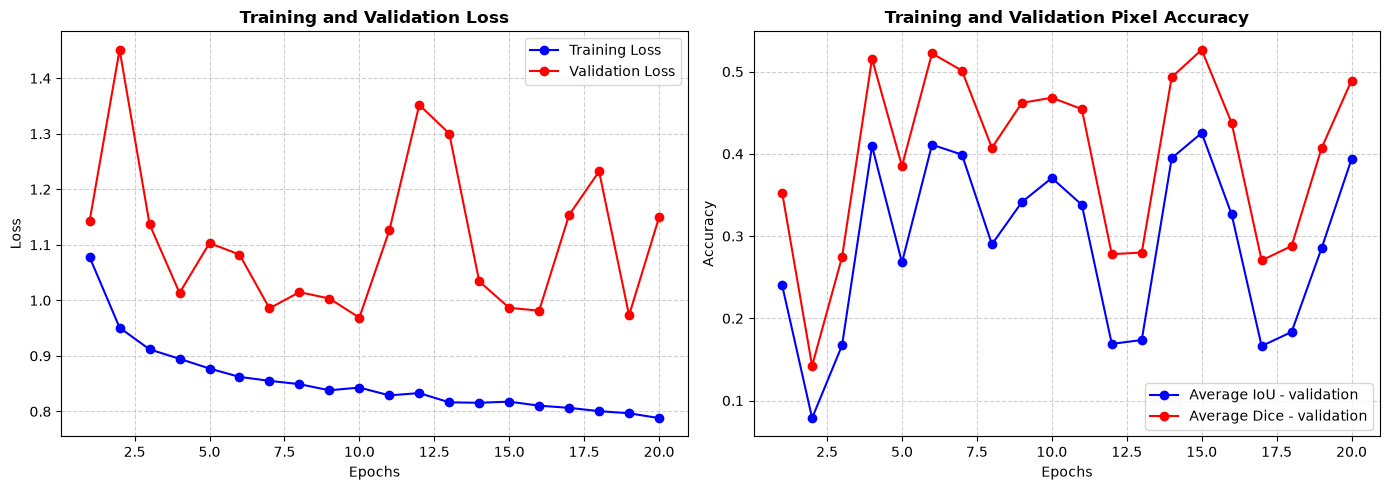

In [ ]:
plot_history(history)

In [ ]:
model.eval()

UNet(
  (inc): DoubleConv(
    (net): Sequential(
      (0): Conv2d(35, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (down1): Sequential(
    (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (1): DoubleConv(
      (net): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, a

## ResNetUNet

In [ ]:
# Assume `model` is your instantiated PyTorch U-Net architecture
model = ResNetUNet(in_channels=35,num_classes=4,max_drop_path=0.2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=500, 
    warm_up_epochs=5,
    criterion= MaskedCrossEntropyLoss(ignore_index=-100),
    optimizer = optim.Adam(model.parameters(), lr=1e-3), # try later with optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2) 
    patience = 10,
    device=device,
    save_path="G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_model_resnetunet.pt"
)


Epoch 01/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch [0/500] | Train Loss: 1.0480 | Val Loss: 1.1377 | Val mIoU: 0.2211 | Val mDice: 0.3305
--> Validation loss decreased (inf --> 1.1377). Saving model...


Epoch [1/500] | Train Loss: 0.9321 | Val Loss: 1.2578 | Val mIoU: 0.1464 | Val mDice: 0.2451
--> Validation loss did not improve. Early stopping counter: 1/10


Epoch 03/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch [2/500] | Train Loss: 0.8895 | Val Loss: 1.1928 | Val mIoU: 0.2551 | Val mDice: 0.3576
--> Validation loss did not improve. Early stopping counter: 2/10


...

Epoch [35/500] | Train Loss: 0.7646 | Val Loss: 0.9974 | Val mIoU: 0.4005 | Val mDice: 0.5018
--> Validation loss did not improve. Early stopping counter: 7/10


Epoch 37/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch [36/500] | Train Loss: 0.7615 | Val Loss: 1.0579 | Val mIoU: 0.2359 | Val mDice: 0.3506
--> Validation loss did not improve. Early stopping counter: 8/10


Epoch [37/500] | Train Loss: 0.7528 | Val Loss: 1.2021 | Val mIoU: 0.2429 | Val mDice: 0.3607
--> Validation loss did not improve. Early stopping counter: 9/10


Epoch [38/500] | Train Loss: 0.7702 | Val Loss: 0.9861 | Val mIoU: 0.2626 | Val mDice: 0.3830
--> Validation loss did not improve. Early stopping counter: 10/10
/nEarly stopping triggered after 38 epochs as validation loss did not decrease for 10 consecutive iterations.


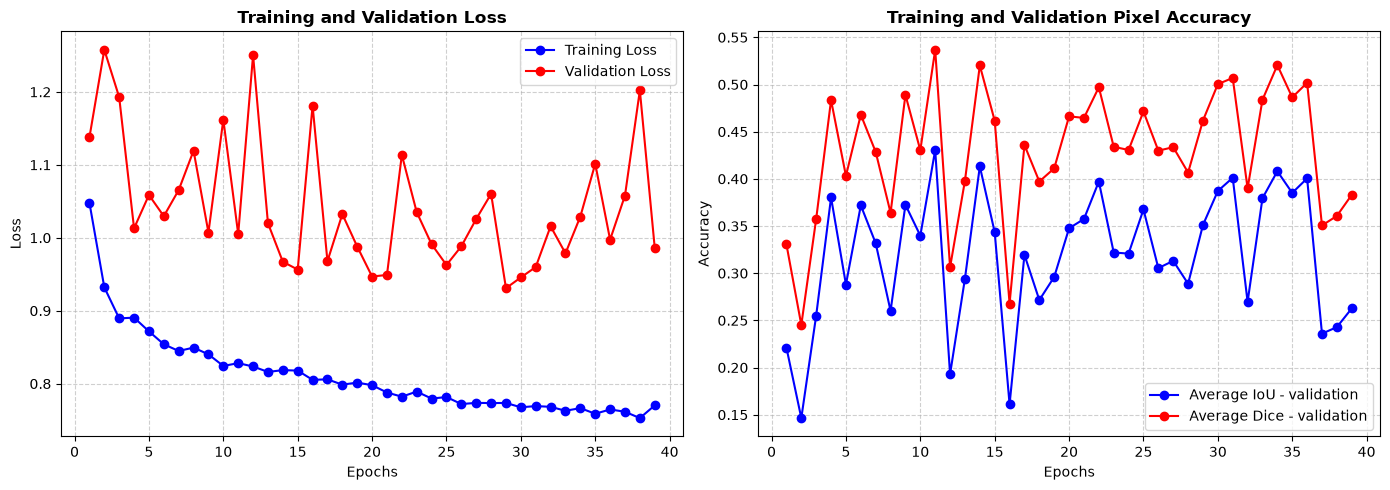

In [19]:
plot_history(history)

In [ ]:
model.eval()

## SK-ResNeXTUNet

In [ ]:
# Assume `model` is your instantiated PyTorch U-Net architecture
model = SKResNeXtUNet(in_channels=35,num_classes=4,drop_rate=0.2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=500, 
    warm_up_epochs=5,
    criterion= MaskedCrossEntropyLoss(ignore_index=-100),
    optimizer = optim.Adam(model.parameters(), lr=1e-3), # try later with optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2) 
    patience = 10,
    device=device,
    save_path="G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_model_SKResNeXtUNet.pt"
)


Epoch [0/500] | Train Loss: 1.0735 | Val Loss: 1.1369 | Val mIoU: 0.4035 | Val mDice: 0.5129
--> Validation loss decreased (inf --> 1.1369). Saving model...


Epoch [1/500] | Train Loss: 0.9611 | Val Loss: 1.1060 | Val mIoU: 0.4142 | Val mDice: 0.5167
--> Validation loss decreased (1.1369 --> 1.1060). Saving model...


Epoch [2/500] | Train Loss: 0.9484 | Val Loss: 1.2929 | Val mIoU: 0.1367 | Val mDice: 0.2122
--> Validation loss did not improve. Early stopping counter: 1/10


Epoch [3/500] | Train Loss: 0.9472 | Val Loss: 1.0879 | Val mIoU: 0.4090 | Val mDice: 0.5097
--> Validation loss decreased (1.1060 --> 1.0879). Saving model...


Epoch [4/500] | Train Loss: 0.9080 | Val Loss: 1.0055 | Val mIoU: 0.3846 | Val mDice: 0.4803
--> Validation loss decreased (1.0879 --> 1.0055). Saving model...


...

Epoch [10/500] | Train Loss: 0.8739 | Val Loss: 1.0720 | Val mIoU: 0.3011 | Val mDice: 0.4317
--> Validation loss did not improve. Early stopping counter: 6/10


Epoch [11/500] | Train Loss: 0.8685 | Val Loss: 1.0698 | Val mIoU: 0.3465 | Val mDice: 0.4521
--> Validation loss did not improve. Early stopping counter: 7/10


Epoch [12/500] | Train Loss: 0.8559 | Val Loss: 1.3269 | Val mIoU: 0.3785 | Val mDice: 0.4709
--> Validation loss did not improve. Early stopping counter: 8/10


Epoch [13/500] | Train Loss: 0.8581 | Val Loss: 1.0757 | Val mIoU: 0.2582 | Val mDice: 0.3633
--> Validation loss did not improve. Early stopping counter: 9/10


Epoch [14/500] | Train Loss: 0.8647 | Val Loss: 1.0873 | Val mIoU: 0.3832 | Val mDice: 0.4772
--> Validation loss did not improve. Early stopping counter: 10/10
/nEarly stopping triggered after 14 epochs as validation loss did not decrease for 10 consecutive iterations.


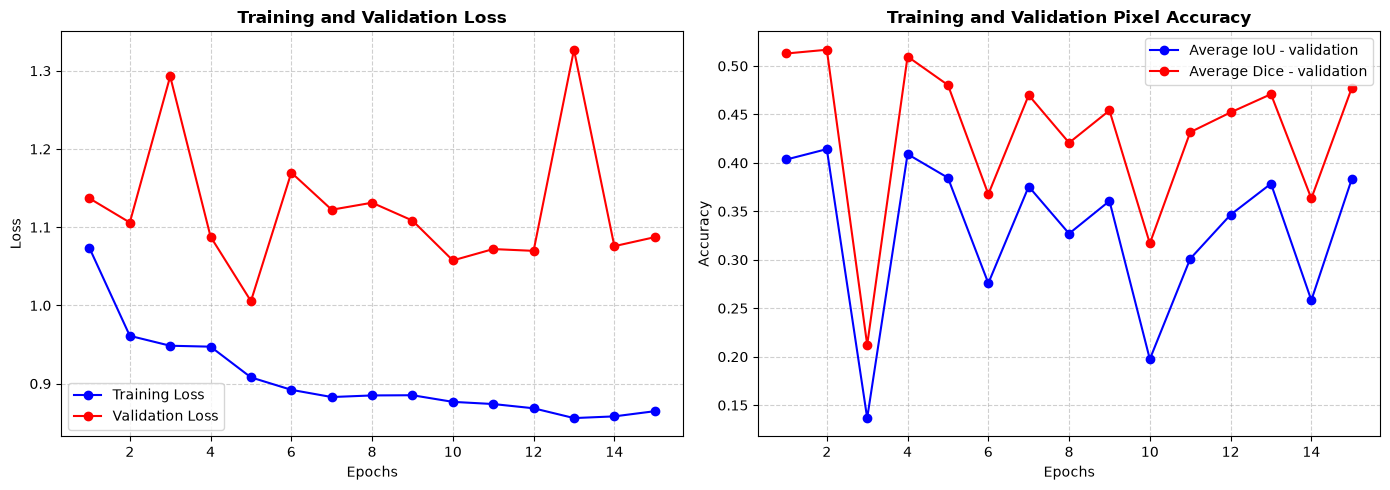

In [71]:
plot_history(history)

In [72]:
model.eval()

SKResNeXtUNet(
  (enc1): Sequential(
    (0): Conv2d(35, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): SKConv(
    (convs): ModuleList(
      (0): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(2, 2), dilation=(2, 2), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (fc): Linear(in_features=128, out_features=32, bias=True)
    (fcs): ModuleList(
      (0-1): 2 x Lin

## Segformer

In [19]:
# Assume `model` is your instantiated PyTorch U-Net architecture
model = SegFormerFeatureModel(
    in_channels=35,
    num_classes=4,            # Change to your target class count
    architecture="nvidia/mit-b0" # Options: mit-b0, mit-b1, mit-b2, etc.
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=500, 
    warm_up_epochs=5,
    criterion= MaskedCrossEntropyLoss(ignore_index=-100),
    optimizer = optim.Adam(model.parameters(), lr=1e-3), # try later with optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2) 
    patience = 10,
    device=device,
    save_path="G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_model_SKResNeXtUNet.pt"
)


Epoch 01/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch [0/500] | LR [0.000664] | Train Loss: 1.1122 | Val Loss: 1.3308 | Val mIoU: 0.1058 | Val mDice: 0.1803
--> Validation loss decreased (inf --> 1.3308). Saving model...


Epoch [1/500] | LR [0.000098] | Train Loss: 0.9743 | Val Loss: 1.0557 | Val mIoU: 0.3763 | Val mDice: 0.4791
--> Validation loss decreased (1.3308 --> 1.0557). Saving model...


Epoch 03/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]


Epoch [2/500] | LR [0.000098] | Train Loss: 0.9365 | Val Loss: 1.0605 | Val mIoU: 0.3532 | Val mDice: 0.4557
--> Validation loss did not improve. Early stopping counter: 1/10


...

Epoch [8/500] | LR [0.000693] | Train Loss: 0.8999 | Val Loss: 1.0017 | Val mIoU: 0.3944 | Val mDice: 0.5052
--> Validation loss decreased (1.0284 --> 1.0017). Saving model...


Epoch [9/500] | LR [0.000998] | Train Loss: 0.9244 | Val Loss: 1.2886 | Val mIoU: 0.1139 | Val mDice: 0.1923
--> Validation loss did not improve. Early stopping counter: 1/10


Epoch 11/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]


Epoch [10/500] | LR [0.000603] | Train Loss: 0.9049 | Val Loss: 1.1463 | Val mIoU: 0.2047 | Val mDice: 0.3241
--> Validation loss did not improve. Early stopping counter: 2/10


KeyboardInterrupt: 

In [ ]:
plot_history(history)

In [ ]:
model.eval()

## TransUNet

In [20]:
model = TransUNet512(
        in_channels=35,
        out_channels=4,
        img_size=(512, 512),
        embed_dim=768,
        num_layers=6,   # Adjusted for demo speed; set to 12 for standard ViT-B configuration
        num_heads=12
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

model, history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=500, 
    warm_up_epochs=5,
    criterion= MaskedCrossEntropyLoss(ignore_index=-100),
    optimizer = optim.Adam(model.parameters(), lr=1e-3), # try later with optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2) 
    patience = 10,
    device=device,
    save_path="G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_model_SKResNeXtUNet.pt"
)


Epoch 01/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]

Epoch [0/500] | LR [0.000664] | Train Loss: 1.0781 | Val Loss: 1.3187 | Val mIoU: 0.3546 | Val mDice: 0.4486
--> Validation loss decreased (inf --> 1.3187). Saving model...


Epoch [1/500] | LR [0.000098] | Train Loss: 0.9619 | Val Loss: 1.0398 | Val mIoU: 0.3690 | Val mDice: 0.4744
--> Validation loss decreased (1.3187 --> 1.0398). Saving model...


Epoch 03/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]



Epoch [2/500] | LR [0.000098] | Train Loss: 0.9204 | Val Loss: 1.0382 | Val mIoU: 0.3518 | Val mDice: 0.4643
--> Validation loss decreased (1.0398 --> 1.0382). Saving model...


Epoch [3/500] | LR [0.000664] | Train Loss: 0.9305 | Val Loss: 1.7673 | Val mIoU: 0.0325 | Val mDice: 0.0613
--> Validation loss did not improve. Early stopping counter: 1/10


Epoch 05/500 [Train]:   0%|          | 0/200 [00:00<?, ?it/s]



KeyboardInterrupt: 

In [ ]:
plot_history(history)

In [ ]:
model.eval()

# 11. Model Inference & Visualization

## UNET

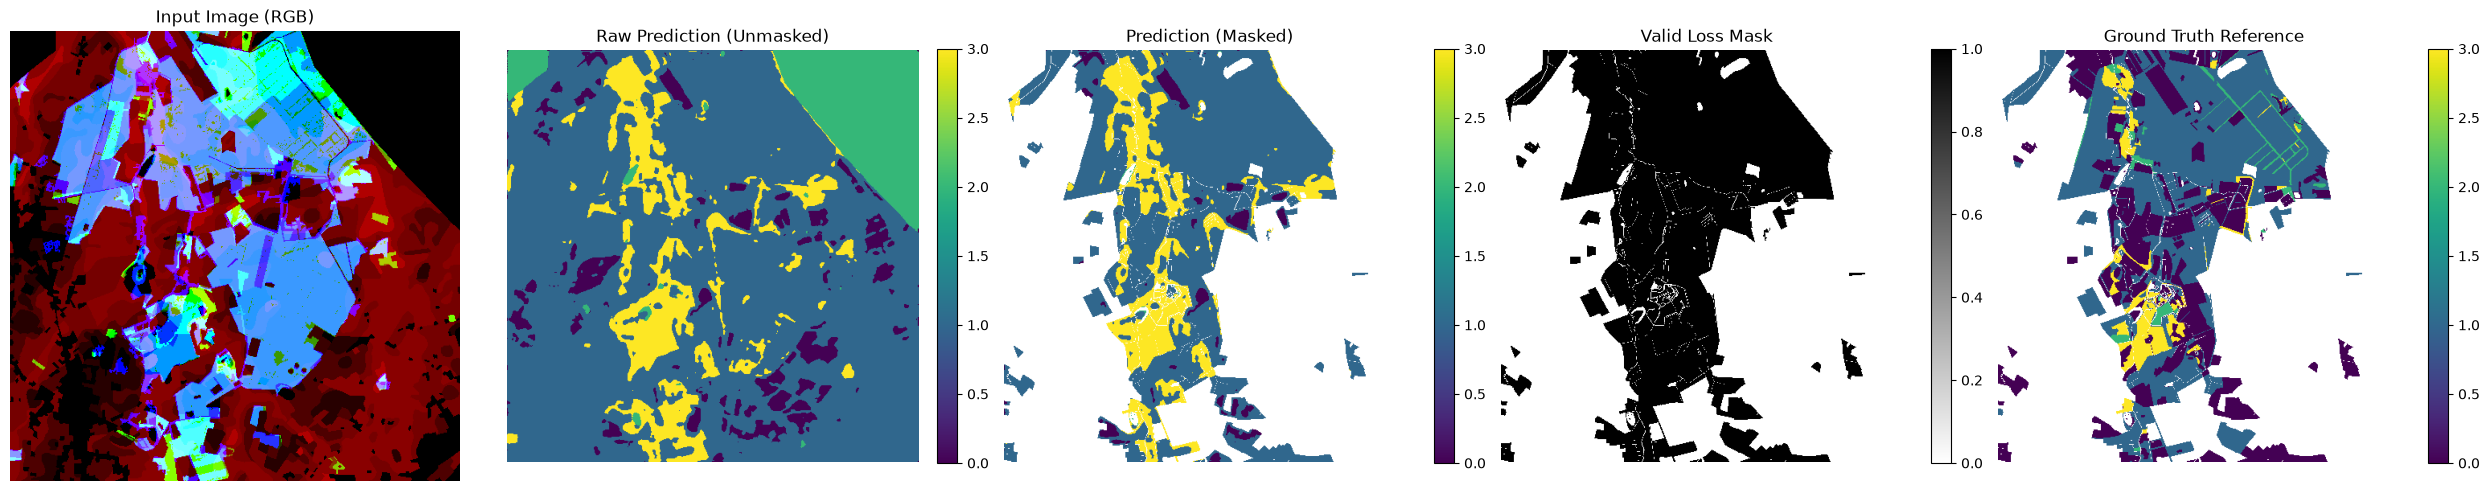

In [ ]:
# -------------------------------------------------------------------------
# 1. Setup Device & Model (Replace UNet/Model class with your actual model)
# -------------------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


model = UNet(in_channels=35,num_classes=4,drop_rate=0.2).to(device)
model.load_state_dict(torch.load("G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_model.pt", map_location=device))
model.eval()

# -------------------------------------------------------------------------
# 2. Fetch a single sample from the test set
# -------------------------------------------------------------------------
sample_idx = 10  # Index of the sample to visualize
x_tensor, target_tensor, valid_mask_tensor = test_dataset[sample_idx]

# Add batch dimension and move to device
input_batch = x_tensor.unsqueeze(0).to(device)  # Shape: (1, C, H, W)

# -------------------------------------------------------------------------
# 3. Perform Inference
# -------------------------------------------------------------------------
with torch.no_grad():
    output = model(input_batch)  # Expected shape: (1, num_classes, H, W) or (1, H, W)

    # Handle multi-class segmentation (logits/argmax) vs binary/single-channel
    if output.ndim == 4 and output.shape[1] > 1:
        pred_mask = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()
    elif output.ndim == 4 and output.shape[1] == 1:
        pred_mask = (
            (torch.sigmoid(output) > 0.5).squeeze(0).squeeze(0).cpu().numpy()
        )
    else:
        pred_mask = output.squeeze(0).cpu().numpy()

# Convert ground truth tensors to numpy arrays
target_img = target_tensor.numpy()  # Shape: (H, W)
valid_mask = valid_mask_tensor.numpy()  # Shape: (H, W)
input_img = x_tensor.numpy()  # Shape: (C, H, W)

# -------------------------------------------------------------------------
# 4. Prepare Input Image for Display
# -------------------------------------------------------------------------
# Select channels to display as an RGB composite (e.g., channels 0, 1, 2)
if input_img.shape[0] >= 3:
    display_rgb = np.moveaxis(input_img[:3, :, :], 0, -1)
    # Min-Max normalize for display purposes
    min_val, max_val = display_rgb.min(), display_rgb.max()
    if max_val > min_val:
        display_rgb = (display_rgb - min_val) / (max_val - min_val)
else:
    display_rgb = input_img[0, :, :]

# Mask out predictions outside the valid spatial region for cleaner plot
masked_pred = np.where(valid_mask > 0, pred_mask, np.nan)

# -------------------------------------------------------------------------
# 5. Visualization (Updated to 5 panels)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

# Plot 1: Input Image
if display_rgb.ndim == 3:
    axes[0].imshow(display_rgb)
    axes[0].set_title("Input Image (RGB)")
else:
    axes[0].imshow(display_rgb, cmap="gray")
    axes[0].set_title("Input Image (Ch 0)")
axes[0].axis("off")

# Plot 2: Raw Model Prediction (NO MASKING)
im1 = axes[1].imshow(pred_mask, cmap="viridis")
axes[1].set_title("Raw Prediction (Unmasked)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Plot 3: Masked Model Prediction
im2 = axes[2].imshow(masked_pred, cmap="viridis")
axes[2].set_title("Prediction (Masked)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

# Plot 4: Valid Loss Mask
im3 = axes[3].imshow(valid_mask, cmap="binary")
axes[3].set_title("Valid Loss Mask")
axes[3].axis("off")
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

# Plot 5: Ground Truth Reference Target
masked_target = np.where(target_img == -100, np.nan, target_img)
im4 = axes[4].imshow(masked_target, cmap="viridis")
axes[4].set_title("Ground Truth Reference")
axes[4].axis("off")
plt.colorbar(im4, ax=axes[4], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## ResNetUNet

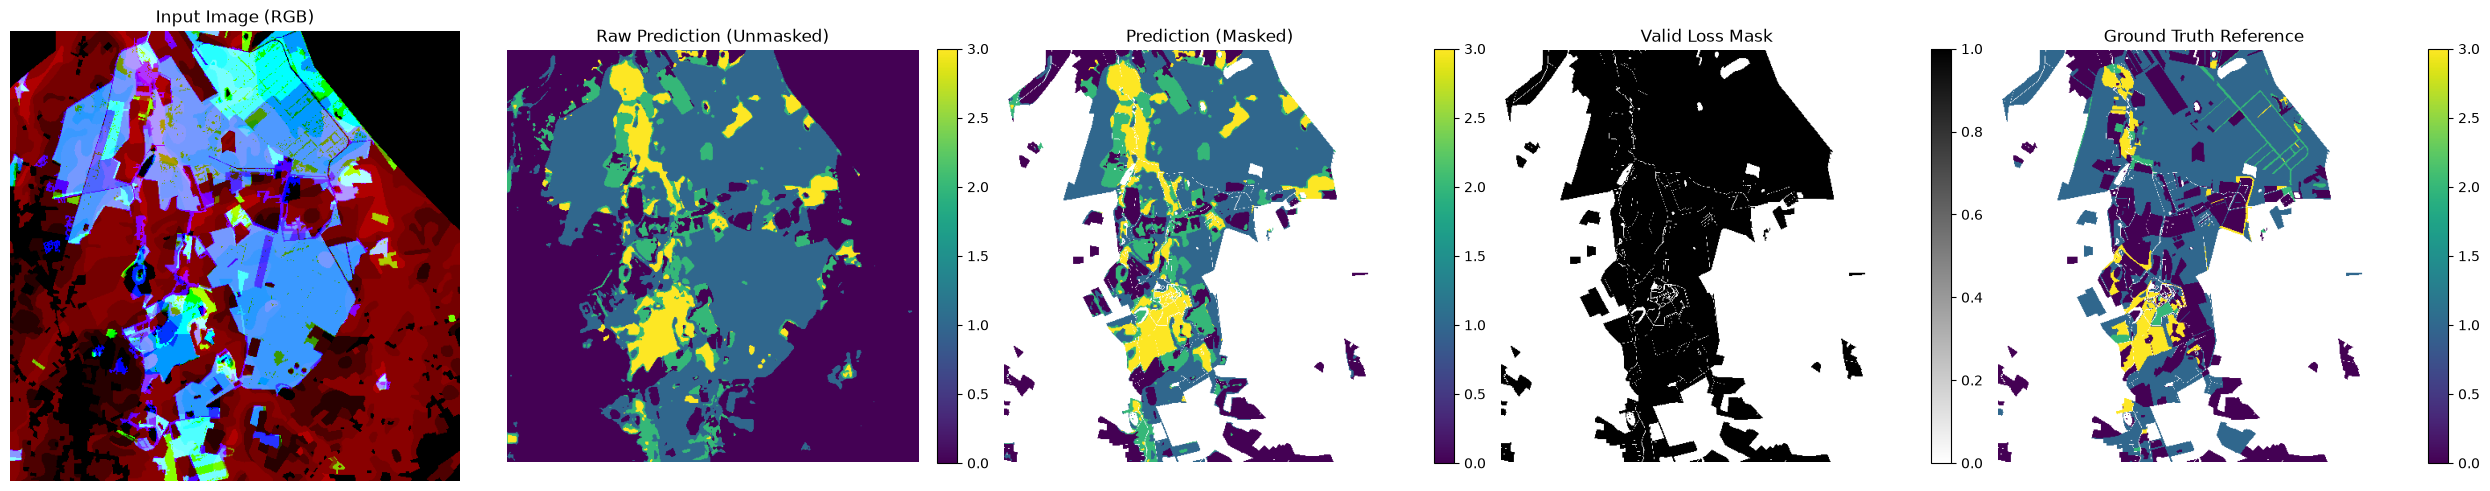

In [ ]:
# -------------------------------------------------------------------------
# 1. Setup Device & Model (Replace UNet/Model class with your actual model)
# -------------------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


model = ResNetUNet(in_channels=35,num_classes=4,max_drop_path=0.2).to(device)
model.load_state_dict(torch.load("G:/Gedeelde drives/PRJ_SlimmeBeeldverwerking/PRJ_2026_SlimmeBeeldverwerking/Slimmebeeldverwerking/Bossenkansenkaart/Boshabitat_referentielaag/Bossenkansenkaart/best_model_resnetunet.pt", map_location=device))
model.eval()

# -------------------------------------------------------------------------
# 2. Fetch a single sample from the test set
# -------------------------------------------------------------------------
sample_idx = 10  # Index of the sample to visualize
x_tensor, target_tensor, valid_mask_tensor = test_dataset[sample_idx]

# Add batch dimension and move to device
input_batch = x_tensor.unsqueeze(0).to(device)  # Shape: (1, C, H, W)

# -------------------------------------------------------------------------
# 3. Perform Inference
# -------------------------------------------------------------------------
with torch.no_grad():
    output = model(input_batch)  # Expected shape: (1, num_classes, H, W) or (1, H, W)

    # Handle multi-class segmentation (logits/argmax) vs binary/single-channel
    if output.ndim == 4 and output.shape[1] > 1:
        pred_mask = torch.argmax(output, dim=1).squeeze(0).cpu().numpy()
    elif output.ndim == 4 and output.shape[1] == 1:
        pred_mask = (
            (torch.sigmoid(output) > 0.5).squeeze(0).squeeze(0).cpu().numpy()
        )
    else:
        pred_mask = output.squeeze(0).cpu().numpy()

# Convert ground truth tensors to numpy arrays
target_img = target_tensor.numpy()  # Shape: (H, W)
valid_mask = valid_mask_tensor.numpy()  # Shape: (H, W)
input_img = x_tensor.numpy()  # Shape: (C, H, W)

# -------------------------------------------------------------------------
# 4. Prepare Input Image for Display
# -------------------------------------------------------------------------
# Select channels to display as an RGB composite (e.g., channels 0, 1, 2)
if input_img.shape[0] >= 3:
    display_rgb = np.moveaxis(input_img[:3, :, :], 0, -1)
    # Min-Max normalize for display purposes
    min_val, max_val = display_rgb.min(), display_rgb.max()
    if max_val > min_val:
        display_rgb = (display_rgb - min_val) / (max_val - min_val)
else:
    display_rgb = input_img[0, :, :]

# Mask out predictions outside the valid spatial region for cleaner plot
masked_pred = np.where(valid_mask > 0, pred_mask, np.nan)

# -------------------------------------------------------------------------
# 5. Visualization (Updated to 5 panels)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

# Plot 1: Input Image
if display_rgb.ndim == 3:
    axes[0].imshow(display_rgb)
    axes[0].set_title("Input Image (RGB)")
else:
    axes[0].imshow(display_rgb, cmap="gray")
    axes[0].set_title("Input Image (Ch 0)")
axes[0].axis("off")

# Plot 2: Raw Model Prediction (NO MASKING)
im1 = axes[1].imshow(pred_mask, cmap="viridis")
axes[1].set_title("Raw Prediction (Unmasked)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# Plot 3: Masked Model Prediction
im2 = axes[2].imshow(masked_pred, cmap="viridis")
axes[2].set_title("Prediction (Masked)")
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

# Plot 4: Valid Loss Mask
im3 = axes[3].imshow(valid_mask, cmap="binary")
axes[3].set_title("Valid Loss Mask")
axes[3].axis("off")
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

# Plot 5: Ground Truth Reference Target
masked_target = np.where(target_img == -100, np.nan, target_img)
im4 = axes[4].imshow(masked_target, cmap="viridis")
axes[4].set_title("Ground Truth Reference")
axes[4].axis("off")
plt.colorbar(im4, ax=axes[4], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# Extra: selective inference and uncertainty with seapig package

## Performed with ResNetUNet

In [ ]:
# Fit seapig Score on Training Set Embeddings
score = EuclideanScore(k=5, stat="mean")
score.fit(model=model, loaders={"train": train_loader, "cal": val_loader})

# 4. Set Threshold to Keep Desired Coverage (e.g., retain 90% of validation samples)
score.set_threshold(q=0.90)

# 5. Perform Selective Prediction on Test Data
results = score.select(model=model, loader=test_loader)

# Output dictionary format:
# results['selected']: Tensor of booleans (True = Accept, False = Abstain/Reject)
# results['score']: Uncertainty score per batch item

Iterating over loader: 100%|██████████| 19/19 [00:35<00:00,  1.89s/it]


In [61]:
results['selected']


tensor([ True,  True,  True,  True,  True,  True,  True,  True,  True, False,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True, False,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True, False,  True,  True,  True,
         True, False,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True], device='cuda:0')

In [67]:
selected = results["selected"].float()

pct_true = selected.mean().item() * 100
pct_false = (1 - selected.mean().item()) * 100

print(f"Accepted (True) : {pct_true:.2f}%")
print(f"Rejected (False): {pct_false:.2f}%")

Accepted (True) : 94.74%
Rejected (False): 5.26%


In [62]:
results['score']

tensor([4.0858, 1.6010, 2.2669, 2.4204, 3.0316, 3.8462, 2.8585, 4.1064, 4.4000,
        5.3334, 3.6878, 2.1229, 2.2396, 2.4271, 2.8509, 3.6361, 3.7248, 3.7425,
        4.3423, 4.2539, 4.2093, 3.6225, 3.5378, 2.4927, 1.7597, 2.4352, 2.9702,
        3.0005, 3.1610, 0.1668, 1.2041, 1.8147, 4.3487, 4.7505, 1.6303, 1.8789,
        1.7545, 3.1090, 3.7853, 2.3582, 4.3086, 2.1020, 1.6316, 2.1206, 2.7356,
        3.1707, 5.0691, 1.6516, 1.9196, 3.5375, 3.0309, 5.3028, 2.2603, 2.0625,
        2.3895, 1.9794, 4.0517, 1.7803, 1.5750, 1.6654, 1.1785, 2.1450, 2.8354,
        1.8675, 1.7362, 1.6896, 1.9650, 2.6171, 3.1051, 2.4567, 2.4992, 1.4932,
        2.7638, 2.7879, 1.7841, 1.6902], device='cuda:0')

In [ ]:
class Model(LightningModule):

    def __init__(self, model: torch.nn.Module):
        super().__init__()
        self.model = model
        # Pass ignore_index so missing/invalid ground truth labels are excluded from IoU calculation
        self.test_metrics = JaccardIndex(
            task="multiclass", num_classes=4, ignore_index=-100
        )

    def forward(self, batch: tuple[torch.Tensor, torch.Tensor]):
        return self.model(batch)

    def extract(self, batch: tuple[torch.Tensor, torch.Tensor]):
        outputs = self.model.extract(batch)
        return {"label": batch[1]} | outputs

    def test_step(self, batch, batch_idx):
        # Unpack batch
        images, targets = batch[0], batch[1]

        # Forward pass logits shape: (B, num_classes, H, W)
        logits = self(images)

        # Update metric with predictions and targets
        preds = torch.argmax(logits, dim=1)
        self.test_metrics.update(preds, targets)
        self.log(
            "test_iou", self.test_metrics, on_step=False, on_epoch=True, prog_bar=True
        )


trainer = Trainer(accelerator="cpu")
task = Model(model=model)

sel_task = SelectiveInferenceTask(task=task, score=score)

metrics = trainer.test(sel_task, dataloaders=test_loader)
preds = trainer.predict(sel_task, dataloaders=test_loader)
print(preds)

GPU available: True (cuda), used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


Testing DataLoader 0: 100%|██████████| 19/19 [00:55<00:00,  0.35it/s]

c:\ProgramData\anaconda3\envs\slimmebeeldverw\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=23` in the `DataLoader` to improve performance.



────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
          Test metric                   DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  full/MulticlassJaccardIndex        0.3044958710670471
rejected/MulticlassJaccardIndex      0.29967907071113586
selected/MulticlassJaccardIndex      0.30292606353759766
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Predicting DataLoader 0: 100%|██████████| 19/19 [00:58<00:00,  0.32it/s]
[{'prediction': tensor([[[[ 1.1517e+00,  1.6067e+00,  1.3325e+00,  ...,  1.0868e+00,
            7.9274e-01,  5.7307e-01],
          [ 1.5509e+00,  2.4417e+00,  2.0598e+00,  ...,  1.2998e+00,
            9.7044e-01,  4.2283e-01],
          [ 1.4491e+00,  2.3320e+00,  1.9333e+00,  ...,  1.4087e+00,
            9.8224e-01,  3.9660e-01],
   